<a href="https://colab.research.google.com/github/sashawrk4-pylyp/Python-Sales-Performance-Analyssis/blob/main/Python_for_DA_Module_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sales Performance Analysis

У проєкті проаналізовано замовлення за період з 01.01.2010 до 23.07.2017. Мета — визначити, які товарні категорії, країни та канали збуту формують найбільший дохід і валовий прибуток, як змінюються продажі з часом і чи пов’язаний час до відправки з прибутком замовлення.

Загальні показники охоплюють увесь період. Для аналізу річної динаміки та сезонності використано сім повних років — 2010–2016. Грошові суми наведено в умовних одиницях, оскільки валюту в даних не вказано.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
plt.style.use("bmh")

In [ ]:
# Підключаємо Google Drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip -o "/content/drive/MyDrive/Jupyter/dataset.zip" -d "/content/dataset"

Archive:  /content/drive/MyDrive/Jupyter/dataset.zip
  inflating: /content/dataset/13. Final project/countries.csv  
  inflating: /content/dataset/13. Final project/products.csv  
  inflating: /content/dataset/13. Final project/events.csv  


In [ ]:
events = pd.read_csv("/content/dataset/13. Final project/events.csv")
products = pd.read_csv("/content/dataset/13. Final project/products.csv")
countries = pd.read_csv("/content/dataset/13. Final project/countries.csv", keep_default_na=False)

# **Data Overview**

In [ ]:
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
products.head()

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


In [ ]:
countries.head()

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


## Дані та зв’язки між таблицями

events — таблиця замовлень. Order ID ідентифікує замовлення, Order Date і Ship Date містять дати оформлення та відправки. Order Priority позначає пріоритет, Sales Channel — канал продажу. Country Code і Product ID пов’язують замовлення з країною та категорією товару. Units Sold — кількість проданих одиниць, Unit Price — ціна продажу однієї одиниці, Unit Cost — її собівартість.

products — довідник товарних категорій. Поле id містить код, а item_type — назву категорії. Ключ з’єднання: events["Product ID"] → products["id"].

countries — довідник країн. name містить назву країни, alpha-2 і alpha-3 — її дво- та трилітерний коди, region і sub-region — регіон і субрегіон. Ключ з’єднання: events["Country Code"] → countries["alpha-3"].

# **Data Cleaning**

In [ ]:
# Перевіряємо дані в таблиці events
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [ ]:
events["Order Date"] = pd.to_datetime(events["Order Date"], format="%m/%d/%Y")
events["Ship Date"] = pd.to_datetime(events["Ship Date"], format="%m/%d/%Y")

# Прибираємо зайві пробіли та уніфікуємо регістр
events["Order Priority"] = events["Order Priority"].str.strip().str.upper()
events["Sales Channel"] = events["Sales Channel"].str.strip().str.capitalize()
events["Country Code"] = events["Country Code"].str.strip().str.upper().replace("", pd.NA)

events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1330 non-null   int64         
 1   Order Date      1330 non-null   datetime64[ns]
 2   Ship Date       1330 non-null   datetime64[ns]
 3   Order Priority  1330 non-null   object        
 4   Country Code    1248 non-null   object        
 5   Product ID      1330 non-null   int64         
 6   Sales Channel   1330 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1330 non-null   float64       
 9   Unit Cost       1330 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 104.0+ KB


In [ ]:
# Видаляємо рядки без кількості проданих одиниць
rows_before = len(events)
events = events.dropna(subset=["Units Sold"]).copy()

print("Рядків до очищення:", rows_before)
print("Видалено рядків:", rows_before - len(events))
print("Рядків після очищення:", len(events))

Рядків до очищення: 1330
Видалено рядків: 2
Рядків після очищення: 1328


Було видалено 2 рядки з відсутніми значеннями Units Sold, оскільки цей показник необхідний для подальшого розрахунку доходу, собівартості та прибутку.

In [ ]:
print(events.isna().sum())

Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         0
Unit Price         0
Unit Cost          0
dtype: int64


In [ ]:
# Перевіряємо пропуски в коді країни
missing_country_code = events["Country Code"].isna().sum()
missing_country_share = missing_country_code / len(events) * 100

print(f"Замовлення без коду країни: {missing_country_code} ({missing_country_share:.2f}%)")

# Перевіряємо заповнені коди країн за довідником
country_codes = events["Country Code"].dropna()
unmatched_codes = country_codes[~country_codes.isin(countries["alpha-3"])].unique()

print("Коди поза довідником:", sorted(unmatched_codes))

Замовлення без коду країни: 82 (6.17%)
Коди поза довідником: []


У 82 замовленнях (6,17%) відсутній код країни. Ці рядки не видалялися, оскільки вони містять інші необхідні дані та враховуються в загальних показниках продажів і прибутку. Водночас через відсутність коду країни вони не входять до географічної розбивки за країнами та регіонами.

In [ ]:
# Перевіряємо дані в таблиці products
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


In [ ]:
# Перевіряємо дані в таблиці countries
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     249 non-null    object
 2   alpha-3     249 non-null    object
 3   region      249 non-null    object
 4   sub-region  249 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


In [ ]:
# Перевіряємо порожні клітинки
print((countries == "").sum())

name          0
alpha-2       0
alpha-3       0
region        1
sub-region    1
dtype: int64


Під час читання таблиці countries використано keep_default_na=False, щоб зберегти дволітерний код Намібії NA. За замовчуванням pandas сприймає NA як пропущене значення. З цим параметром порожні клітинки зчитуються як порожні рядки. Перевірка виявила дві такі клітинки в записі Антарктиди — по одній у стовпцях region і sub-region. Запис залишено в довіднику.

In [ ]:
# Перевіряємо дублікати
print("events:", events.duplicated().sum())
print("Повторні Order ID:", events["Order ID"].duplicated().sum())
print("products:", products.duplicated().sum())
print("countries:", countries.duplicated().sum())

events: 0
Повторні Order ID: 0
products: 0
countries: 0


Перевірка показала, що в усіх трьох таблицях дублікати відсутні, тому додаткове видалення рядків не потрібне.

In [ ]:
# Перевіряємо аномалії
display(events[["Units Sold", "Unit Price", "Unit Cost"]].describe())

# Перевіряємо, чи дата відправки не раніше дати замовлення
invalid_dates = (events["Ship Date"] < events["Order Date"]).sum()

# Перевіряємо, чи собівартість не перевищує ціну
invalid_prices = (events["Unit Cost"] > events["Unit Price"]).sum()

print("Ship Date earlier than Order Date:", invalid_dates)
print("Unit Cost greater than Unit Price:", invalid_prices)

,Units Sold,Unit Price,Unit Cost
count,1328.000000,1328.000000,1328.000000
mean,4952.201807,264.913245,187.211521
std,2905.198996,217.386320,176.187801
min,2.000000,9.330000,6.920000
25%,2356.750000,81.730000,35.840000
50%,4962.000000,154.060000,97.440000
75%,7459.500000,437.200000,263.330000
max,9999.000000,668.270000,524.960000


Ship Date earlier than Order Date: 0
Unit Cost greater than Unit Price: 0


Перевірка статистичних показників та можливих аномалій показала, що значення кількості проданих одиниць, ціни й собівартості не мають очевидних відхилень. Також не виявлено замовлень, у яких дата відправки передує даті замовлення, або собівартість перевищує ціну продажу.

In [ ]:
events["Order Priority"].value_counts(dropna=False)

,count
Order Priority,
M,353
H,335
L,334
C,306


In [ ]:
events["Sales Channel"].value_counts(dropna=False)

,count
Sales Channel,
Offline,665
Online,663


Форматування категоріальних значень було стандартизовано: зайві пробіли в Order Priority видалено, а значення Sales Channel приведено до єдиного формату.

In [ ]:
# Перевіряємо розмір таблиці events
print("events:", events.shape)

# Перевіряємо розмір таблиці products
print("products:", products.shape)

# Перевіряємо розмір таблиці countries
print("countries:", countries.shape)

events: (1328, 10)
products: (12, 2)
countries: (249, 5)


In [ ]:
# Об'єднуємо таблицю events з таблицею products
df = events.merge(
    products,
    left_on="Product ID",
    right_on="id",
    how="left",
    validate="many_to_one")

print("Розмір df:", df.shape)
display(df.head())

Розмір df: (1328, 12)


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,id,item_type
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,2103,Cereal
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,2103,Cereal
2,101025998,2014-07-18,2014-08-11,M,NaN,7940,Online,4693.0,668.27,502.54,7940,Household
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,2455,Clothes
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,1270,Beverages


In [ ]:
# Об'єднуємо датафрейм з таблицею countries
df = df.merge(
    countries,
    left_on="Country Code",
    right_on="alpha-3",
    how="left",
    validate="many_to_one")

print("Розмір df:", df.shape)
display(df.head())

Розмір df: (1328, 17)


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,id,item_type,name,alpha-2,alpha-3,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,2103,Cereal,Norway,NO,NOR,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,2103,Cereal,Serbia,RS,SRB,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,NaN,7940,Online,4693.0,668.27,502.54,7940,Household,NaN,NaN,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,2455,Clothes,Montenegro,ME,MNE,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,1270,Beverages,Serbia,RS,SRB,Europe,Southern Europe


Після об'єднання таблиць отримано єдиний датафрейм із 1328 замовленнями, доповнений інформацією про категорії товарів та географію продажів.

In [ ]:
# Видаляємо дублікати ключових колонок та непотрібну інформацію
df = df.drop(columns=["id", "alpha-2", "alpha-3"])
print(df.columns)

Index(['Order ID', 'Order Date', 'Ship Date', 'Order Priority', 'Country Code',
       'Product ID', 'Sales Channel', 'Units Sold', 'Unit Price', 'Unit Cost',
       'item_type', 'name', 'region', 'sub-region'],
      dtype='object')


In [ ]:
# Перейменовуємо колонки для зручності подальшого аналізу
df = df.rename(columns={
    "Order ID": "order_id", "Order Date": "order_date", "Ship Date": "ship_date",
    "Order Priority": "order_priority", "Country Code": "country_code", "Product ID": "product_id",
    "Sales Channel": "sales_channel", "Units Sold": "units_sold", "Unit Price": "unit_price",
    "Unit Cost": "unit_cost", "item_type": "category", "name": "country", "region": "region", "sub-region": "sub_region"})

In [ ]:
# Перевіряємо пропущені значення
print("Пропущені значення:")
print(df.isnull().sum())

# Перевіряємо дублікати
print("Кількість дублікатів:", df.duplicated().sum())

Пропущені значення:
order_id           0
order_date         0
ship_date          0
order_priority     0
country_code      82
product_id         0
sales_channel      0
units_sold         0
unit_price         0
unit_cost          0
category           0
country           82
region            82
sub_region        82
dtype: int64
Кількість дублікатів: 0


Фінальна перевірка показала, що в датафреймі відсутні дублікати та пропуски в основних показниках. 82 пропуски в географічних полях відповідають замовленням без Country Code, які були збережені для розрахунку загальних показників.

In [ ]:
display(df.head())

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,category,country,region,sub_region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,Cereal,Serbia,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,NaN,7940,Online,4693.0,668.27,502.54,Household,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,Clothes,Montenegro,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,Beverages,Serbia,Europe,Southern Europe


# **Data Analysis and Visualization**

In [ ]:
# Розраховуємо загальний дохід від продажів
df["revenue"] = df["units_sold"] * df["unit_price"]

# Розраховуємо загальні витрати на продані товари
df["cost"] = df["units_sold"] * df["unit_cost"]

# Розраховуємо загальний прибуток
df["profit"] = df["revenue"] - df["cost"]

display(df[["units_sold", "unit_price", "unit_cost", "revenue", "cost", "profit"]].head())

,units_sold,unit_price,unit_cost,revenue,cost,profit
0,650.0,205.70,117.11,133705.00,76121.50,57583.50
1,1993.0,205.70,117.11,409960.10,233400.23,176559.87
2,4693.0,668.27,502.54,3136191.11,2358420.22,777770.89
3,1171.0,109.28,35.84,127966.88,41968.64,85998.24
4,7648.0,47.45,31.79,362897.60,243129.92,119767.68


У межах цього аналізу прибуток розраховується як різниця між доходом від продажів і собівартістю реалізованих товарів. Таким чином, отриманий показник відображає валовий прибуток і не враховує інші операційні та адміністративні витрати компанії.

## Key Business Metrics

In [ ]:
# Розраховуємо ключові метрики діяльності компанії
total_orders = df["order_id"].nunique()
total_revenue = df["revenue"].sum()
total_cost = df["cost"].sum()
total_profit = df["profit"].sum()
total_units = df["units_sold"].sum()
total_countries = df["country"].nunique()
total_categories = df["category"].nunique()
average_order_revenue = df["revenue"].mean()

# Виводимо ключові метрики
print("Total Orders:", total_orders)
print("Total Revenue:", total_revenue)
print("Total Cost:", total_cost)
print("Total Profit:", total_profit)
print("Total Units Sold:", total_units)
print("Total Countries:", total_countries)
print("Total Categories:", total_categories)
print("Average Revenue per Order:", average_order_revenue)

# Розраховуємо рентабельність продажів
profit_margin = (total_profit / total_revenue) * 100
print("Profit Margin:", profit_margin, "%")

Total Orders: 1328
Total Revenue: 1702129408.21
Total Cost: 1200694949.21
Total Profit: 501434459.0
Total Units Sold: 6576524.0
Total Countries: 45
Total Categories: 12
Average Revenue per Order: 1281723.9519653614
Profit Margin: 29.45924420207982 %


За аналізований період компанія отримала 1,70 млрд доходу та 501,43 млн валового прибутку. Валова маржа становила 29,46%. У 1 328 замовленнях продано 6 576 524 одиниці товарів із 12 категорій. Середній дохід на замовлення становив 1,28 млн умовних одиниць.

In [ ]:
# Аналіз замовлень без коду країни
unknown_country = df["country_code"].isna()

unknown_orders = unknown_country.sum()
unknown_revenue = df.loc[unknown_country, "revenue"].sum()
unknown_profit = df.loc[unknown_country, "profit"].sum()

print("Orders without country code:", unknown_orders)
print("Share of orders:", round(unknown_orders / len(df) * 100, 2), "%")
print("Revenue without country code:", round(unknown_revenue / 1_000_000, 2), "million")
print("Profit without country code:", round(unknown_profit / 1_000_000, 2), "million")
print("Share of total profit:", round(unknown_profit / total_profit * 100, 2), "%")

Orders without country code: 82
Share of orders: 6.17 %
Revenue without country code: 103.15 million
Profit without country code: 27.73 million
Share of total profit: 5.53 %


## Product Category Analysis

In [ ]:
# Групуємо дані за категоріями товарів
category_sales = df.groupby("category").agg({"revenue": "sum", "cost": "sum", "profit": "sum", "units_sold": "sum"}).sort_values("revenue", ascending=False)

# Розраховуємо маржу для кожної категорії у відсотках
category_sales["margin"] = (category_sales["profit"] / category_sales["revenue"] * 100)
display(category_sales)

,revenue,cost,profit,units_sold,margin
category,,,,,
Office Supplies,4.022140e+08,3.242368e+08,77977176.25,617641.0,19.386987
Household,2.942052e+08,2.212427e+08,72962466.77,440249.0,24.799856
Cosmetics,2.331548e+08,1.404315e+08,92723306.17,533291.0,39.768984
Meat,2.237620e+08,1.934243e+08,30337736.00,530380.0,13.558036
Baby Food,1.436476e+08,8.970659e+07,53940997.16,562706.0,37.550924
Cereal,9.579140e+07,5.453637e+07,41255034.15,465685.0,43.067574
Vegetables,8.974673e+07,5.297073e+07,36776002.72,582544.0,40.977541
Snacks,7.478861e+07,4.776119e+07,27027422.40,490160.0,36.138419
Clothes,6.462655e+07,2.119524e+07,43431314.40,591385.0,67.203514


In [ ]:
# Створюємо копію таблиці для зручного відображення
category_summary = category_sales.copy()

# Переводимо дохід, витрати та прибуток у мільйони
category_summary[["revenue", "cost", "profit"]] = (category_summary[["revenue", "cost", "profit"]] / 1_000_000)

# Округлюємо показники
category_summary = category_summary.round(2)
display(category_summary)

,revenue,cost,profit,units_sold,margin
category,,,,,
Office Supplies,402.21,324.24,77.98,617641.0,19.39
Household,294.21,221.24,72.96,440249.0,24.80
Cosmetics,233.15,140.43,92.72,533291.0,39.77
Meat,223.76,193.42,30.34,530380.0,13.56
Baby Food,143.65,89.71,53.94,562706.0,37.55
Cereal,95.79,54.54,41.26,465685.0,43.07
Vegetables,89.75,52.97,36.78,582544.0,40.98
Snacks,74.79,47.76,27.03,490160.0,36.14
Clothes,64.63,21.20,43.43,591385.0,67.20


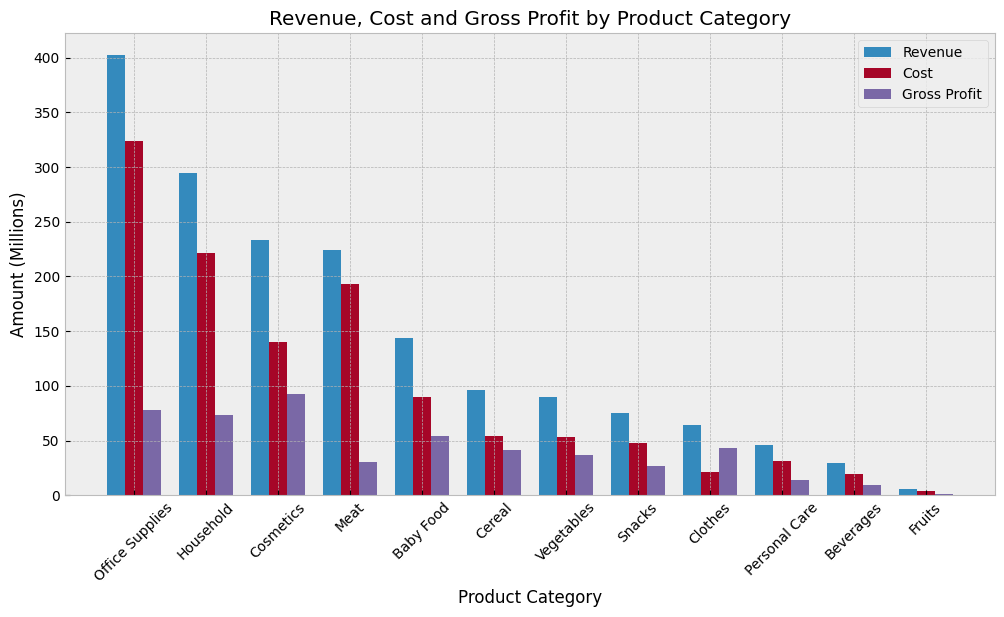

In [ ]:
# Графік "Дохід, витрати та прибуток по категоріях продуктів"
x = np.arange(len(category_sales.index))

plt.figure(figsize=(12, 6))

width = 0.25
plt.bar(
    x - width,
    category_sales["revenue"] / 1_000_000,
    width=width,
    label="Revenue")
plt.bar(
    x,
    category_sales["cost"] / 1_000_000,
    width=width,
    label="Cost")
plt.bar(
    x + width,
    category_sales["profit"] / 1_000_000,
    width=width,
    label="Gross Profit")
plt.title("Revenue, Cost and Gross Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount (Millions)")
plt.xticks(x, category_sales.index, rotation=45)
plt.legend()
plt.show()

Office Supplies забезпечує найбільший дохід серед товарних категорій — близько 402,21 млн, проте її маржа становить лише 19,39%. Cosmetics формує найбільший прибуток — близько 92,72 млн — при маржі 39,77%.

Найвища маржа спостерігається у Clothes — 67,20%, хоча частка цієї категорії в загальному доході становить лише близько 3,8%. Водночас Meat має найнижчу маржу — 13,56%, а Household — 24,80%.

Fruits має найнижчий дохід — близько 5,52 млн, проте це пояснюється низькою ціною одиниці товару (9,33), а не обов'язково низькою популярністю: кількість проданих одиниць становить близько 591,7 тис. Маржа категорії — 25,83%.

Отже, для оцінки ефективності товарних категорій важливо враховувати не лише дохід і прибуток, а й маржу та кількість проданих одиниць. Високий дохід не завжди означає високу рентабельність.

## Geographic Analysis

In [ ]:
# Групуємо дані за країнами та сортуємо їх за доходом
country_sales = df.groupby("country").agg(
    revenue=("revenue", "sum"),
    cost=("cost", "sum"),
    profit=("profit", "sum"),
    units_sold=("units_sold", "sum"),
    orders=("order_id", "nunique")).sort_values("revenue", ascending=False)

# Валова маржа країни у відсотках
country_sales["margin_pct"] = 100 * country_sales["profit"] / country_sales["revenue"]

display(country_sales.round(2))

,revenue,cost,profit,units_sold,orders,margin_pct
country,,,,,,
Czech Republic,53543932.14,39908338.36,13635593.78,142446.0,31,25.47
Ukraine,53252317.54,38447391.80,14804925.74,164577.0,33,27.80
Bosnia and Herzegovina,50117508.49,36859905.72,13257602.77,153545.0,33,26.45
Macedonia,49222085.25,35537985.30,13684099.95,203078.0,32,27.80
San Marino,47883708.48,34090715.67,13792992.81,192228.0,40,28.81
Andorra,47756693.17,32346656.54,15410036.63,185686.0,40,32.27
Portugal,47172189.84,35826782.25,11345407.59,124825.0,25,24.05
Malta,47145320.81,32535192.93,14610127.88,173641.0,32,30.99
Russia,46051659.81,32783977.17,13267682.64,165954.0,32,28.81


In [ ]:
# Виводимо 10 країн із найбільшим прибутком
top_10_profit_countries = country_sales.sort_values("profit", ascending=False).head(10)
display(top_10_profit_countries)

,revenue,cost,profit,units_sold,orders,margin_pct
country,,,,,,
Andorra,47756693.17,32346656.54,15410036.63,185686.0,40,32.267805
Ukraine,53252317.54,38447391.80,14804925.74,164577.0,33,27.801467
Malta,47145320.81,32535192.93,14610127.88,173641.0,32,30.989561
San Marino,47883708.48,34090715.67,13792992.81,192228.0,40,28.805189
Hungary,42408249.12,28622018.09,13786231.03,152242.0,25,32.508371
Macedonia,49222085.25,35537985.30,13684099.95,203078.0,32,27.800732
Czech Republic,53543932.14,39908338.36,13635593.78,142446.0,31,25.466179
Russia,46051659.81,32783977.17,13267682.64,165954.0,32,28.810433
Bosnia and Herzegovina,50117508.49,36859905.72,13257602.77,153545.0,33,26.453036


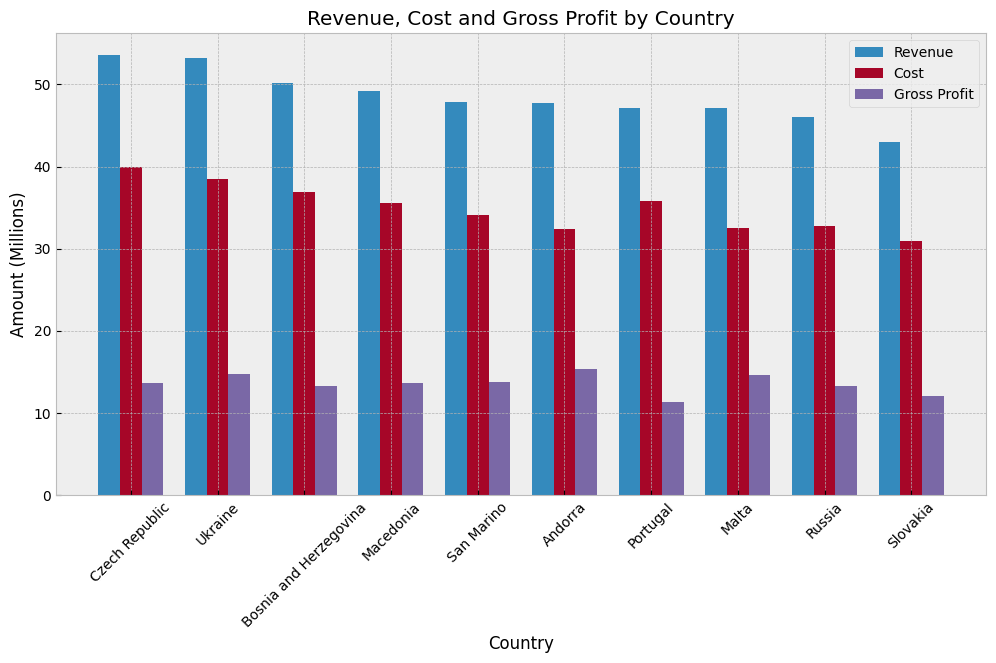

In [ ]:
# Графік "Дохід, витрати та прибуток по країнах"
top_10_countries = country_sales.head(10)
x = np.arange(len(top_10_countries.index))

plt.figure(figsize=(12, 6))

width = 0.25
plt.bar(
    x - width,
    top_10_countries["revenue"] / 1_000_000,
    width=width,
    label="Revenue")
plt.bar(
    x,
    top_10_countries["cost"] / 1_000_000,
    width=width,
    label="Cost")
plt.bar(
    x + width,
    top_10_countries["profit"] / 1_000_000,
    width=width,
    label="Gross Profit")
plt.title("Revenue, Cost and Gross Profit by Country")
plt.xlabel("Country")
plt.ylabel("Amount (Millions)")
plt.xticks(x, top_10_countries.index, rotation=45)
plt.legend()
plt.show()

Для порівняння обсягу продажів країни впорядковано за доходом. Перше місце посіла Чехія — 53,54 млн за 31 замовлення. За валового прибутку 13,64 млн її маржа становила 25,47%.

Андорра посіла шосте місце за доходом (47,76 млн за 40 замовлень), але перше за валовим прибутком (15,41 млн). Її маржа становила 32,27% — на 6,80 відсоткового пункту вище, ніж у Чехії. Друге й третє місця за валовим прибутком посіли Україна (14,80 млн) і Мальта (14,61 млн).

In [ ]:
# Групуємо дані за регіонами та розраховуємо основні показники
region_sales = df.groupby("region").agg({
    "revenue": "sum", "cost": "sum", "profit": "sum", "units_sold": "sum"}).sort_values("revenue", ascending=False)
display(region_sales)

,revenue,cost,profit,units_sold
region,,,,
Europe,1.505653e+09,1.057096e+09,4.485568e+08,5761244.0
Asia,9.333089e+07,6.817863e+07,2.515225e+07,410427.0


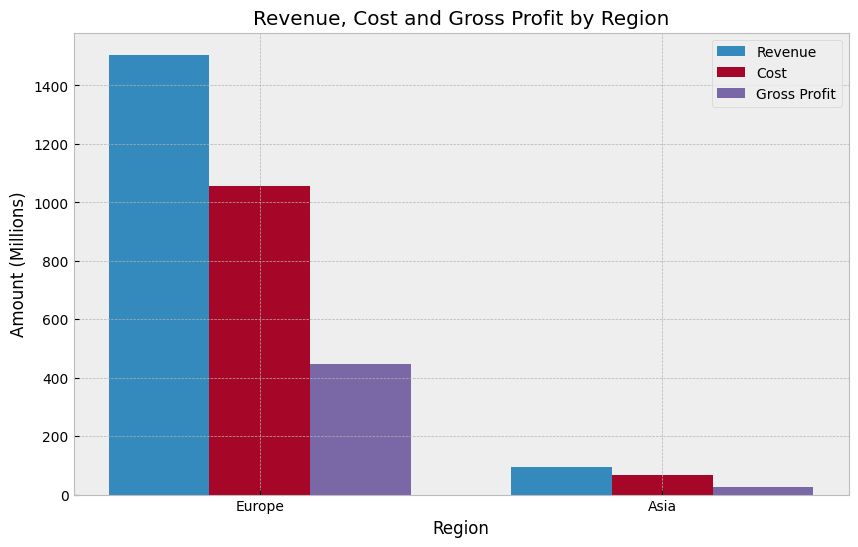

In [ ]:
# Графік "Дохід, витрати та прибуток по регіонах"
x = np.arange(len(region_sales.index))

plt.figure(figsize=(10, 6))

width = 0.25
plt.bar(
    x - width,
    region_sales["revenue"] / 1_000_000,
    width=width,
    label="Revenue")
plt.bar(
    x,
    region_sales["cost"] / 1_000_000,
    width=width,
    label="Cost")
plt.bar(
    x + width,
    region_sales["profit"] / 1_000_000,
    width=width,
    label="Gross Profit")
plt.title("Revenue, Cost and Gross Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount (Millions)")
plt.xticks(x, region_sales.index)
plt.legend()
plt.show()

Європа забезпечила 1 505,65 млн доходу (88,5% загального доходу компанії) та 448,56 млн валового прибутку. На Азію припало 93,33 млн доходу й 25,15 млн валового прибутку.

Ще 82 замовлення (6,17% усіх замовлень) не мають коду країни. На них припадає 103,15 млн доходу та 27,73 млн валового прибутку. Ці суми враховано в загальних показниках компанії. Саме на них регіональні підсумки менші за загальні.

## Sales Channel Analysis

In [ ]:
# Групуємо дані за каналами продажів
channel_sales = df.groupby("sales_channel").agg({
    "revenue": "sum", "cost": "sum", "profit": "sum", "units_sold": "sum"}).sort_values("revenue", ascending=False)
display(channel_sales)

,revenue,cost,profit,units_sold
sales_channel,,,,
Offline,8.717606e+08,6.182941e+08,2.534665e+08,3320363.0
Online,8.303688e+08,5.824008e+08,2.479679e+08,3256161.0


In [ ]:
# Розраховуємо частки доходу, прибутку та маржу за каналами продажів
channel_sales["revenue_share"] = (
    channel_sales["revenue"] / channel_sales["revenue"].sum() * 100)

channel_sales["profit_share"] = (
    channel_sales["profit"] / channel_sales["profit"].sum() * 100)

channel_sales["margin"] = (
    channel_sales["profit"] / channel_sales["revenue"] * 100)

display(channel_sales.round(2))

,revenue,cost,profit,units_sold,revenue_share,profit_share,margin
sales_channel,,,,,,,
Offline,8.717606e+08,6.182941e+08,2.534665e+08,3320363.0,51.22,50.55,29.08
Online,8.303688e+08,5.824008e+08,2.479679e+08,3256161.0,48.78,49.45,29.86


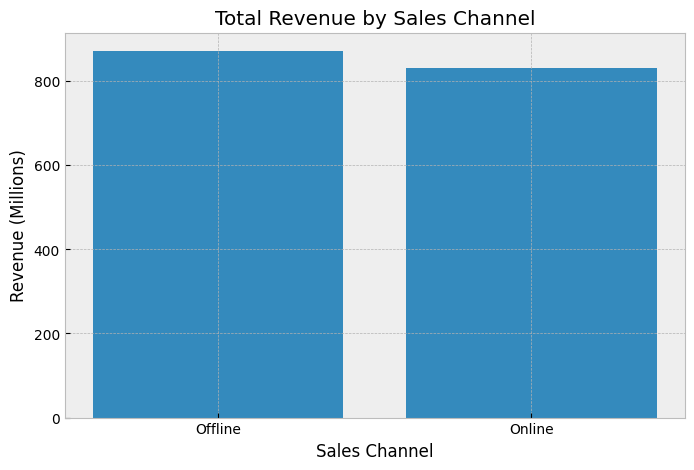

In [ ]:
# Створюємо графік доходу за каналами продажів
plt.figure(figsize=(8, 5))

plt.bar(
    channel_sales.index,
    channel_sales["revenue"] / 1_000_000)
plt.title("Total Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (Millions)")
plt.show()

Офлайн-канал забезпечив 871,76 млн доходу (51,22%) і 253,47 млн валового прибутку (50,55%). На онлайн-канал припало 830,37 млн доходу (48,78%) і 247,97 млн валового прибутку (49,45%).

Офлайн лідирував за загальним доходом і валовим прибутком. Онлайн мав дещо вищу валову маржу — 29,9% проти 29,1%, тобто приносив трохи більше валового прибутку на кожну одиницю доходу.

## Shipping Time Analysis

Час до відправки — це кількість днів між датою замовлення та датою його відправки.

In [ ]:
# Розраховуємо кількість днів між замовленням та відправкою
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

# Групуємо дані за категоріями та розраховуємо середній час відправки
category_shipping = df.groupby("category")["shipping_days"].mean().sort_values(ascending=False)
display(category_shipping)

,shipping_days
category,
Cereal,27.184466
Office Supplies,26.707317
Baby Food,26.339286
Cosmetics,25.912281
Meat,25.909091
Snacks,25.543689
Fruits,24.419643
Beverages,24.123967
Household,23.938144


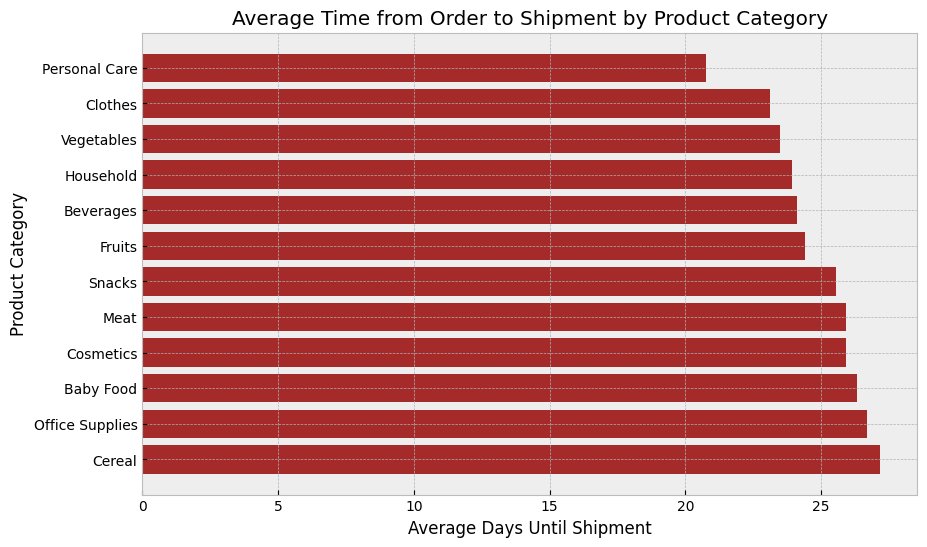

In [ ]:
# Графік "Середній час від замовлення до відправки за категоріями"
category_shipping = category_shipping.sort_values()

plt.figure(figsize=(10, 6))

plt.barh(category_shipping.index, category_shipping.values, color="brown")
plt.title("Average Time from Order to Shipment by Product Category")
plt.xlabel("Average Days Until Shipment")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.show()

Найкоротший середній час до відправки має Personal Care (20,76 дня), найдовший — Cereal (27,18 дня). Різниця становить 6,42 дня. Окремі замовлення відправляли через 0–50 днів, тому лише за середніми значеннями складно визначити, чи є в певній категорії систематичні затримки.

In [ ]:
# Групуємо дані за країнами та розраховуємо середній час до відправки й кількість замовлень
country_shipping = df.groupby("country").agg(
    average_shipping_days=("shipping_days", "mean"),
    order_count=("order_id", "count")).sort_values("average_shipping_days", ascending=False)
display(country_shipping)

,average_shipping_days,order_count
country,,
Hungary,32.640000,25
Georgia,29.695652,23
Austria,28.500000,28
Slovakia,28.466667,30
Luxembourg,27.750000,28
Lithuania,27.560000,25
Poland,27.464286,28
Russia,27.375000,32
Monaco,26.846154,13


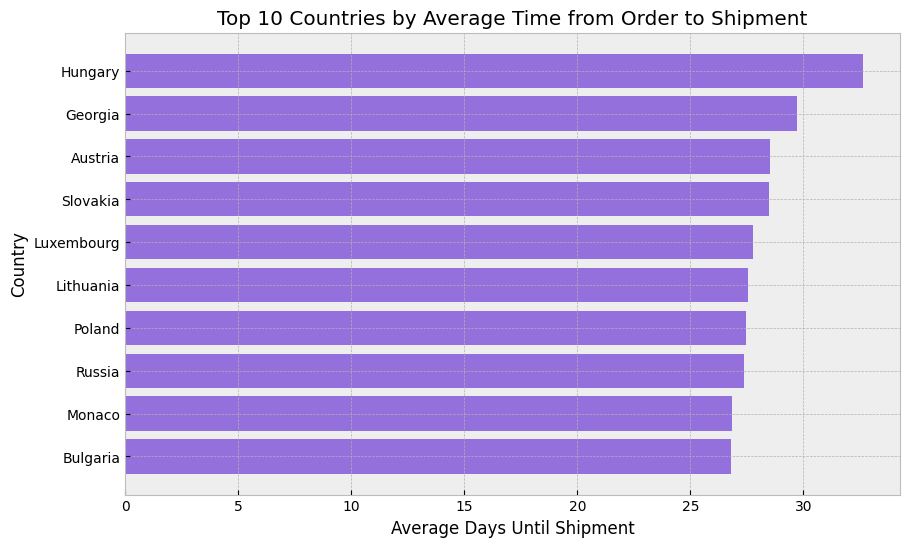

In [ ]:
# Графік 10 країн із найдовшим середнім часом від замовлення до відправки
top_10_shipping_countries = country_shipping.head(10).sort_values(by="average_shipping_days")

plt.figure(figsize=(10, 6))

plt.barh(top_10_shipping_countries.index, top_10_shipping_countries["average_shipping_days"], color="mediumpurple")
plt.title("Top 10 Countries by Average Time from Order to Shipment")
plt.xlabel("Average Days Until Shipment")
plt.ylabel("Country")
plt.show()

Найдовше до відправки в середньому чекали замовлення в Угорщині — 32,64 дня за 25 замовленнями. Далі йдуть Грузія (29,70 дня за 23 замовленнями) та Австрія (28,50 дня за 28 замовленнями). За такої кількості спостережень кілька тривалих відправок можуть помітно вплинути на місце країни в рейтингу.

In [ ]:
# Групуємо дані за регіонами та розраховуємо середній час відправки
region_shipping = df.groupby("region")["shipping_days"].mean().sort_values(ascending=False)
display(region_shipping)

,shipping_days
region,
Asia,26.085366
Europe,24.790378


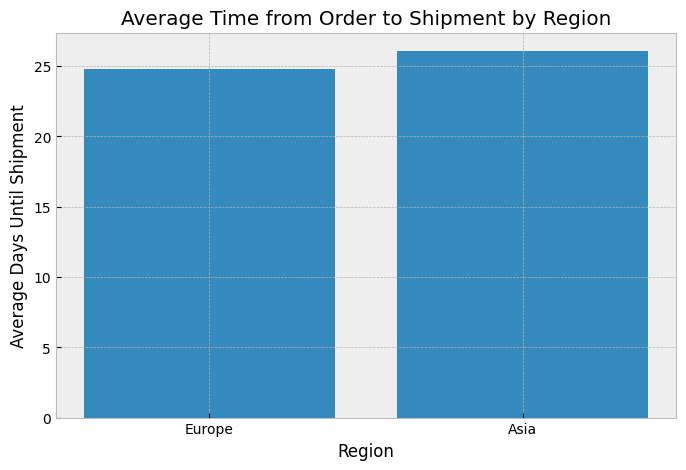

In [ ]:
# Сортуємо регіони за часом від замовлення до відправки
region_shipping = region_shipping.sort_values()

plt.figure(figsize=(8, 5))

plt.bar(region_shipping.index, region_shipping.values)
plt.title("Average Time from Order to Shipment by Region")
plt.xlabel("Region")
plt.ylabel("Average Days Until Shipment")
plt.show()

Середній час до відправки становив 24,79 дня в Європі та 26,09 дня в Азії. Різниця між регіонами — 1,30 дня.

Pearson r: 0.0603
R²: 0.36%


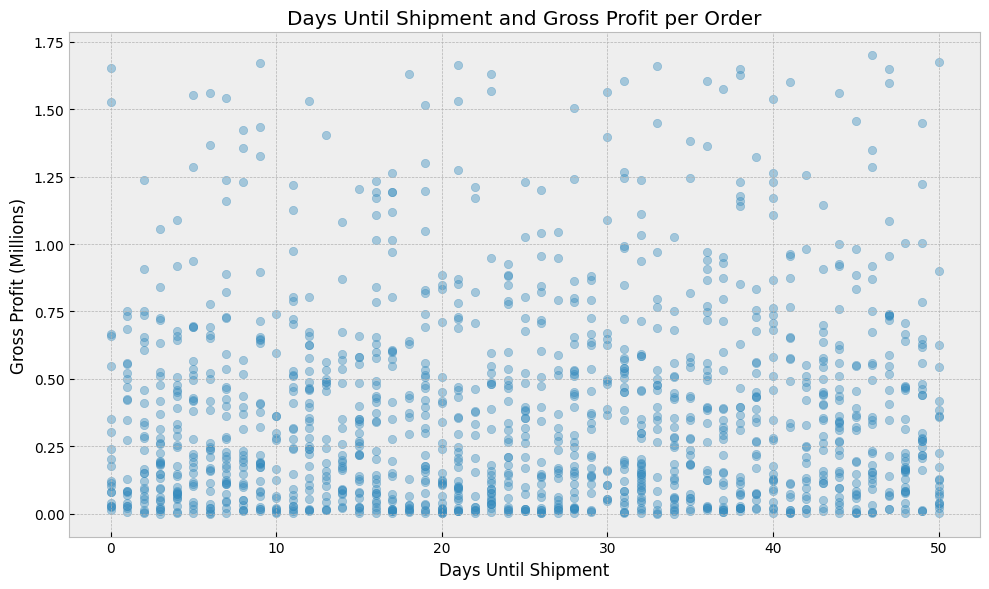

In [ ]:
# Кореляція між часом до відправки та валовим прибутком замовлення
correlation = df["shipping_days"].corr(df["profit"])

print(f"Pearson r: {correlation:.4f}")
print(f"R²: {correlation ** 2:.2%}")

plt.figure(figsize=(10, 6))
plt.scatter(df["shipping_days"], df["profit"] / 1_000_000, alpha=0.4)
plt.title("Days Until Shipment and Gross Profit per Order")
plt.xlabel("Days Until Shipment")
plt.ylabel("Gross Profit (Millions)")
plt.tight_layout()
plt.show()

Між часом до відправки та валовим прибутком замовлення майже немає лінійного зв’язку (r = 0,0603). За однакового часу до відправки прибуток замовлень помітно різниться. У простій лінійній моделі час до відправки пояснює лише 0,36% варіації валового прибутку.

## Sales Dynamics

Для порівняння річного доходу використано сім повних календарних років — 2010–2016. Дані за 2017 рік охоплюють лише період до 23 липня.

In [ ]:
# Вибираємо повні календарні роки
df["year"] = df["order_date"].dt.year
yearly_df = df.loc[df["year"].between(2010, 2016)].copy()

# Розраховуємо загальний річний дохід у мільйонах
yearly_total = yearly_df.groupby("year")["revenue"].sum() / 1_000_000
display(yearly_total.rename("revenue_mln").round(2).to_frame())

,revenue_mln
year,
2010,209.38
2011,231.94
2012,285.49
2013,182.96
2014,236.29
2015,227.95
2016,191.52


Серед повних років найвищий дохід припав на 2012 рік — 285,49 млн. У 2013 році дохід знизився до 182,96 млн. Скорочення становило 102,53 млн, або 35,9% від доходу 2012 року. У розрахунок включено всі замовлення за ці роки, зокрема й замовлення без коду країни.

category,Office Supplies,Household,Cosmetics,Meat,Baby Food
year,,,,,
2010,40.78,33.55,25.62,36.10,18.35
2011,58.53,30.09,39.34,30.47,14.52
2012,52.32,43.69,56.66,40.16,28.26
2013,40.86,29.93,14.51,25.90,18.35
2014,56.53,46.09,30.83,23.27,26.00
2015,75.45,46.13,20.54,28.16,19.96
2016,43.53,42.54,18.40,21.26,12.32


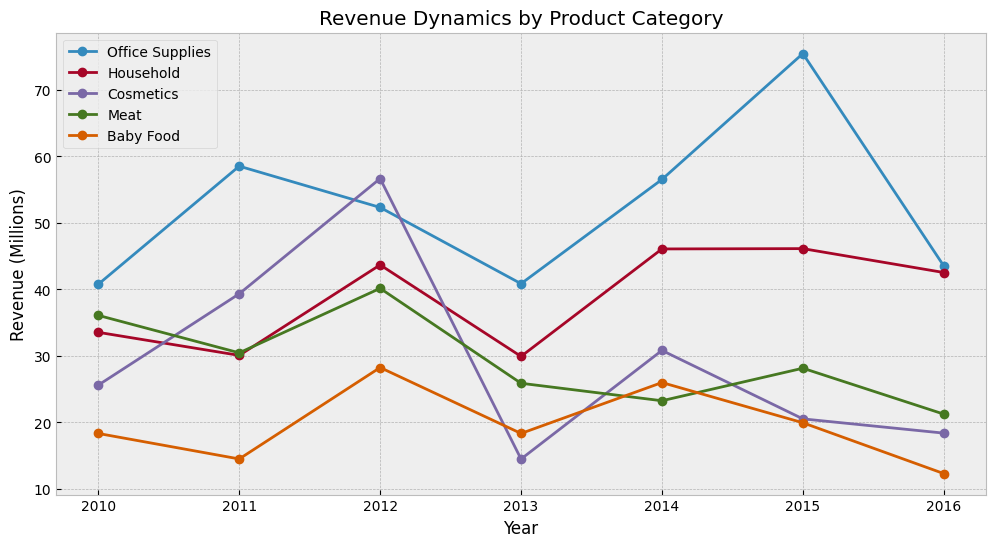

In [ ]:
# Графік "Динаміка доходів за товарними категоріями"

# Вибираємо 5 категорій із найбільшим доходом
top_categories = category_sales.head(5).index

# Групуємо дохід за роками та категоріями
yearly_category_sales = yearly_df.groupby(["year", "category"])["revenue"].sum().unstack()

# Залишаємо лише категорії, наявні в таблиці
top_categories = [
    category for category in top_categories
    if category in yearly_category_sales.columns]

# Виводимо дохід за роками в мільйонах
display((yearly_category_sales[top_categories] / 1_000_000).round(2))

# Створюємо графік
plt.figure(figsize=(12, 6))

for category in top_categories:
    plt.plot(
        yearly_category_sales.index,
        yearly_category_sales[category] / 1_000_000,
        marker="o",
        label=category)
plt.title("Revenue Dynamics by Product Category")
plt.xlabel("Year")
plt.ylabel("Revenue (Millions)")
plt.legend()
plt.show()

Найбільший спад серед п’яти категорій на графіку припав на Cosmetics: з 56,66 млн у 2012 році до 14,51 млн у 2013 році. Це падіння на 42,15 млн — близько 41% загального скорочення доходу компанії. Дохід також знизився в категоріях Meat (на 14,26 млн), Household (на 13,76 млн), Office Supplies (на 11,46 млн) і Baby Food (на 9,91 млн).

country,Czech Republic,Ukraine,Bosnia and Herzegovina,Macedonia,San Marino
year,,,,,
2010,8.11,3.19,1.33,2.29,2.39
2011,15.64,8.95,2.52,0.00,1.25
2012,2.22,13.99,20.51,2.68,9.36
2013,1.42,0.35,4.40,2.85,4.94
2014,14.76,8.03,0.40,6.79,7.14
2015,6.91,5.63,17.91,16.45,6.89
2016,1.78,5.76,3.06,5.26,9.50


country,Czech Republic,Ukraine,Bosnia and Herzegovina,Macedonia,San Marino
year,,,,,
2010,5,2,3,5,4
2011,6,7,4,0,2
2012,6,4,10,3,10
2013,1,1,4,2,4
2014,5,6,2,3,5
2015,5,5,7,7,2
2016,1,4,3,5,9


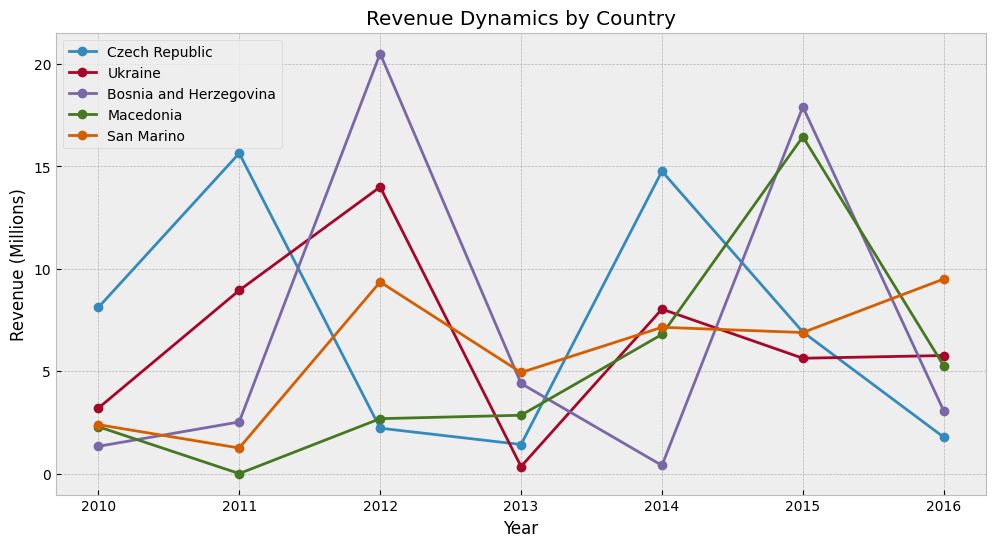

In [ ]:
# Графік "Динаміка доходів по країнах"

# Групуємо дохід за роками та країнами
yearly_country_sales = yearly_df.groupby(["year", "country"])["revenue"].sum().unstack(fill_value=0)

# Вибираємо 5 країн із найбільшим доходом
top_countries = country_sales.head(5).index

# Залишаємо лише країни, наявні в таблиці
top_countries = [
    country for country in top_countries
    if country in yearly_country_sales.columns]

# Виводимо дохід за роками в мільйонах
display((yearly_country_sales[top_countries] / 1_000_000).round(2))

# Кількість замовлень за роками для країн на графіку
yearly_country_orders = (
    yearly_df.groupby(["year", "country"])["order_id"]
    .nunique()
    .unstack(fill_value=0))

display(yearly_country_orders[top_countries])

# Створюємо графік
plt.figure(figsize=(12, 6))

for country in top_countries:
    plt.plot(
        yearly_country_sales.index,
        yearly_country_sales[country] / 1_000_000,
        marker="o",
        label=country)
plt.title("Revenue Dynamics by Country")
plt.xlabel("Year")
plt.ylabel("Revenue (Millions)")
plt.legend()
plt.show()

В Україні у 2012 році чотири замовлення принесли 13,99 млн доходу, а у 2013 році одне замовлення — 0,35 млн. За такої малої кількості замовлень річний дохід суттєво залежить від суми окремої покупки. Тому за цими двома роками складно зробити висновок про стійке падіння попиту.

region,Asia,Europe
year,,
2010,14.04,188.21
2011,4.35,209.86
2012,21.79,245.77
2013,12.33,163.02
2014,12.28,204.70
2015,14.77,199.22
2016,6.24,175.03


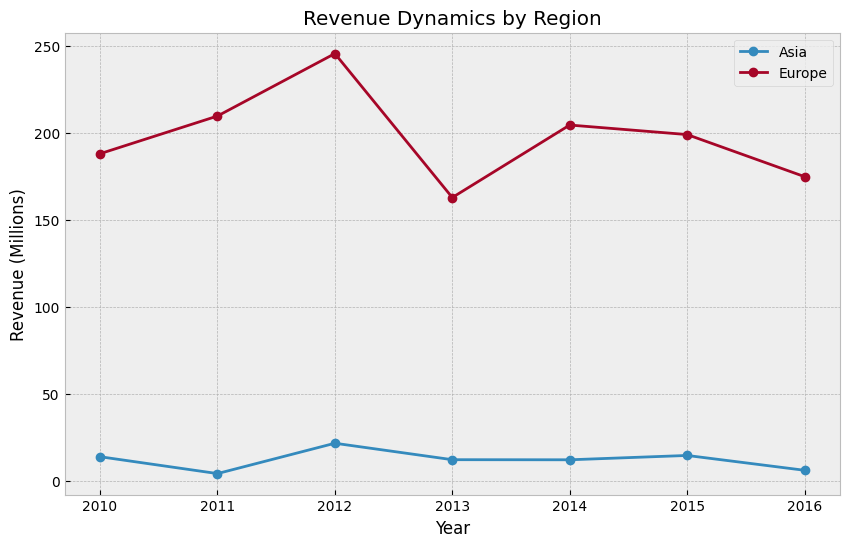

In [ ]:
# Графік "Динаміка доходів по регіонах"
# Групуємо дохід за роками та регіонами
yearly_region_sales = yearly_df.groupby(["year", "region"])["revenue"].sum().unstack()

# Виводимо дохід за роками в мільйонах
display((yearly_region_sales / 1_000_000).round(2))

# Створюємо графік
plt.figure(figsize=(10, 6))

for region in yearly_region_sales.columns:
    plt.plot(
        yearly_region_sales.index,
        yearly_region_sales[region] / 1_000_000,
        marker="o",
        label=region)
plt.title("Revenue Dynamics by Region")
plt.xlabel("Year")
plt.ylabel("Revenue (Millions)")
plt.legend()
plt.show()

З 2012 до 2013 року дохід у Європі знизився з 245,77 до 163,02 млн, а в Азії — з 21,79 до 12,33 млн. Серед замовлень із відомою країною найбільше скорочення припало на Європу — 82,75 млн.

## Revenue by Day of Week

In [ ]:
# Створюємо колонку з назвою дня тижня та групуємо показники
df["weekday"] = df["order_date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"]

weekday_sales = df.groupby("weekday").agg({
    "revenue": "sum",
    "profit": "sum",
    "units_sold": "sum"}).reindex(weekday_order)

# Кількість замовлень і середній чек за днями тижня
weekday_sales["orders"] = df.groupby("weekday")["order_id"].nunique()
weekday_sales["avg_check"] = weekday_sales["revenue"] / weekday_sales["orders"]

display(weekday_sales.round(2))

,revenue,profit,units_sold,orders,avg_check
weekday,,,,,
Monday,2.754685e+08,75790330.12,1027424.0,201,1370489.93
Tuesday,2.135239e+08,65637400.07,863568.0,182,1173208.21
Wednesday,2.612157e+08,72323843.38,900973.0,194,1346472.66
Thursday,2.149222e+08,64325663.17,850351.0,167,1286959.46
Friday,2.638070e+08,79234529.04,866387.0,176,1498903.43
Saturday,2.336411e+08,71435860.49,1015852.0,201,1162393.76
Sunday,2.395510e+08,72686832.73,1051969.0,207,1157251.02


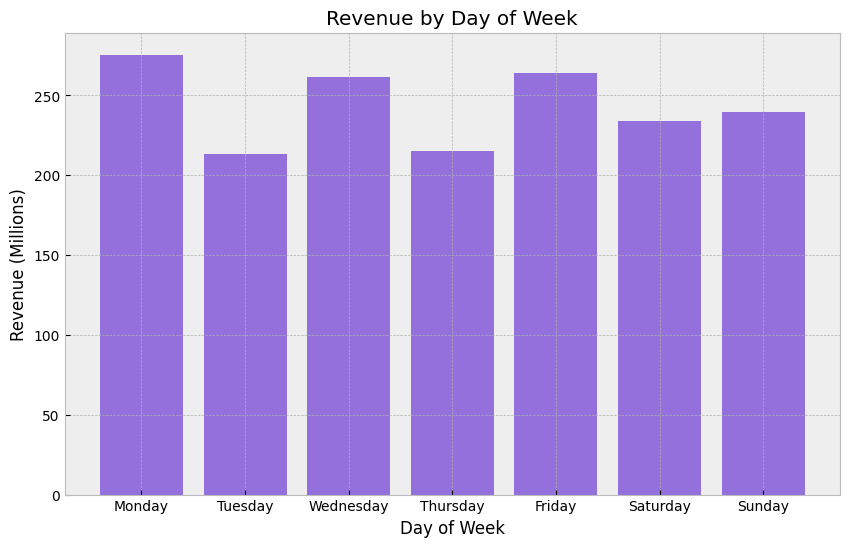

In [ ]:
# Створюємо графік доходу за днями тижня
plt.figure(figsize=(10, 6))

plt.bar(
    weekday_sales.index,
    weekday_sales["revenue"].values / 1_000_000,
    color="mediumpurple")
plt.title("Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Revenue (Millions)")
plt.show()

Найбільший дохід припав на понеділок — 275,47 млн за 201 замовлення. П’ятниця посіла друге місце за доходом (263,81 млн за 176 замовлень), хоча мала найвищий середній чек за тиждень — 1,50 млн проти 1,37 млн у понеділок. Більша кількість замовлень компенсувала нижчий середній чек у понеділок.

За валовим прибутком лідирувала п’ятниця — 79,23 млн проти 75,79 млн у понеділок. Найнижчі суми доходу припали на вівторок (213,52 млн) і четвер (214,92 млн).

## Seasonality Analysis

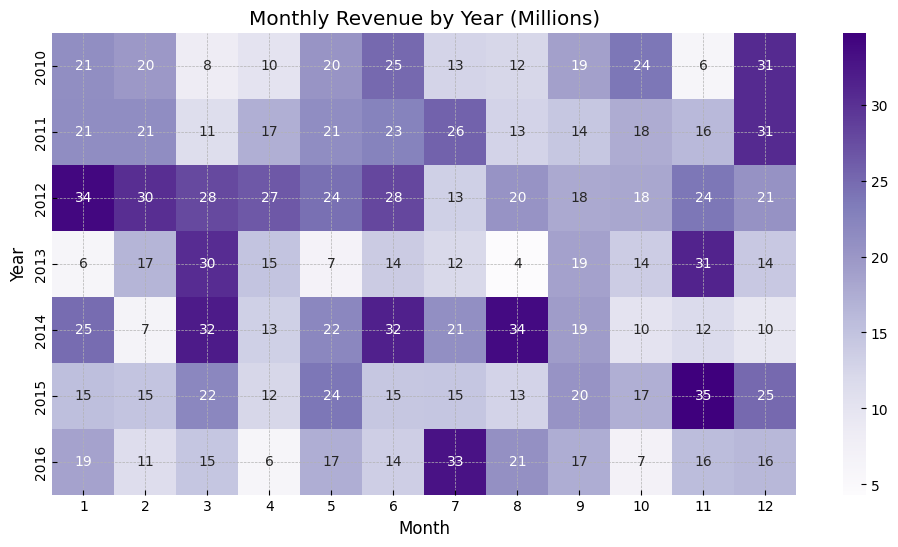

In [ ]:
# Виключаємо неповний 2017 рік
seasonal_df = yearly_df

# Групуємо дохід за роками та місяцями
monthly_revenue = (
    seasonal_df
    .assign(month=lambda d: d["order_date"].dt.month)
    .groupby(["year", "month"])["revenue"]
    .sum()
    .unstack()
    .reindex(columns=range(1, 13))
    .fillna(0))

# Створюємо теплову карту сезонності
plt.figure(figsize=(12, 6))

sns.heatmap(
    monthly_revenue / 1_000_000,
    annot=True,
    fmt=".0f",
    cmap="Purples")

plt.title("Monthly Revenue by Year (Millions)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

Найбільший місячний дохід припав на грудень у 2010 і 2011 роках, на січень у 2012 році, на листопад у 2013 і 2015 роках, на серпень у 2014 році та на липень у 2016 році. За сім років піковими були п’ять різних місяців. Стійкого щорічного піку в одному місяці не видно.

,mean_revenue_mln,std_revenue_mln
month,,
1,20.17,8.55
2,17.26,7.60
3,20.94,9.61
4,14.34,6.45
5,19.42,6.09
6,21.32,7.40
7,18.92,7.94
8,16.74,9.33
9,18.19,1.90


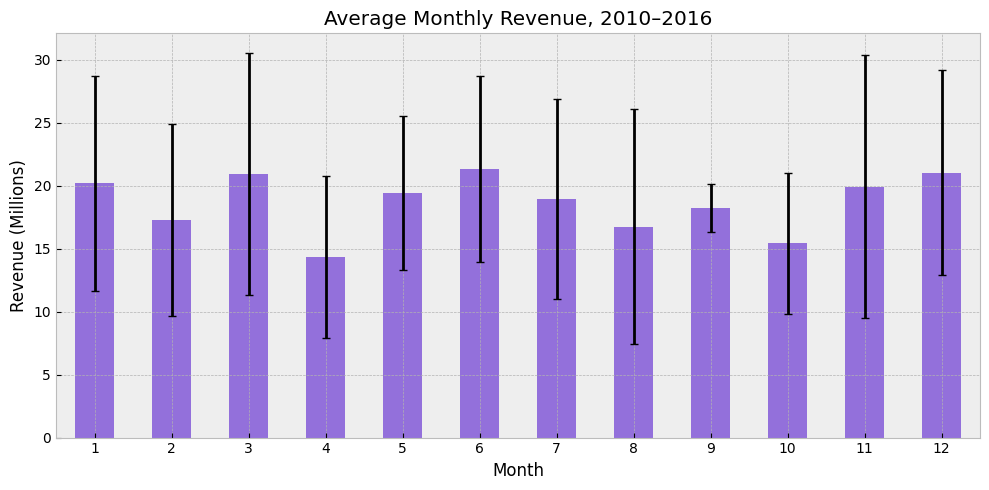

In [ ]:
# Середній дохід кожного календарного місяця та його розкид за 2010–2016 роки
month_avg = monthly_revenue.mean() / 1_000_000
month_std = monthly_revenue.std() / 1_000_000

monthly_summary = pd.DataFrame({
    "mean_revenue_mln": month_avg,
    "std_revenue_mln": month_std})

display(monthly_summary.round(2))

ax = month_avg.plot.bar(
    yerr=month_std,
    capsize=3,
    color="mediumpurple",
    figsize=(10, 5),
    rot=0)
ax.set_title("Average Monthly Revenue, 2010–2016")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (Millions)")
plt.tight_layout()
plt.show()

За 2010–2016 роки середній дохід у вересні становив 18,19 млн, а в листопаді — 19,92 млн. Середні відрізнялися лише на 1,73 млн, проте в листопаді дохід коливався значно сильніше. Стандартне відхилення становило 10,44 млн проти 1,90 млн у вересні — приблизно у 5,5 раза більше. Серед усіх місяців вересень мав найменший розкид, а листопад — найбільший.

Найвищий середній дохід мав червень (21,32 млн), найнижчий — квітень (14,34 млн). Різниця між ними становила 6,98 млн. У восьми з дванадцяти місяців стандартне відхилення між роками перевищувало цю різницю. Разом із тим, що річні піки припадали на п’ять різних місяців, це свідчить, що стійкого сезонного піку в цих даних не видно.

In [ ]:
# Перевіряємо, чи повторюється піковий місяць у кожній категорії
category_months = (
    yearly_df.assign(month=yearly_df["order_date"].dt.month)
    .groupby(["category", "year", "month"], as_index=False)
    .agg(units_sold=("units_sold", "sum"), orders=("order_id", "nunique")))

# Для кожної категорії знаходимо місяць із найбільшою кількістю
# проданих одиниць у кожному році. За рівності зберігаємо обидва піки.
yearly_max = category_months.groupby(["category", "year"])["units_sold"].transform("max")
peak_months = category_months.loc[category_months["units_sold"].eq(yearly_max)]

peak_summary = (
    peak_months.groupby(["category", "month"], as_index=False)
    .agg(years_at_peak=("year", "nunique"), orders_in_peak_months=("orders", "sum")))

most_frequent = peak_summary.groupby("category")["years_at_peak"].transform("max")
display(
    peak_summary.loc[peak_summary["years_at_peak"].eq(most_frequent)]
    .sort_values(["years_at_peak", "category", "month"], ascending=[False, True, True])
    .reset_index(drop=True))

,category,month,years_at_peak,orders_in_peak_months
0,Baby Food,3,2,8
1,Baby Food,6,2,7
2,Beverages,10,2,7
3,Cereal,7,2,5
4,Cereal,10,2,6
5,Clothes,5,2,7
6,Clothes,6,2,6
7,Fruits,3,2,5
8,Household,6,2,5
9,Meat,12,2,6


За 2010–2016 роки в жодній із 12 категорій той самий місяць не був піковим за кількістю проданих одиниць більше ніж у двох із семи років. Наприклад, у категорії Meat грудень лідирував двічі, причому на ці два грудні разом припало лише шість замовлень. У Cosmetics та Office Supplies піковий місяць змінювався щороку. Отже, за цими даними немає достатніх підстав визначити для будь-якої категорії стабільний місяць найвищих продажів.

## Final Conclusion

За період з 01.01.2010 до 23.07.2017 компанія отримала 1,70 млрд умовних грошових одиниць доходу та 501,43 млн валового прибутку. Валова маржа становила 29,46%. За 1 328 замовленнями продано 6,58 млн одиниць товарів із 12 категорій.

**Товари й ринки.** Office Supplies забезпечила найбільший дохід (402,21 млн) із маржею 19,39%. За валовим прибутком лідирувала Cosmetics (92,72 млн), а за маржею — Clothes (67,20%). Продажі охопили 45 відомих країн — 42 у Європі та 3 в Західній Азії. Європа сформувала 88,5% загального доходу. Серед країн Чехія лідирувала за доходом (53,54 млн), а Андорра — за валовим прибутком (15,41 млн).

**Канали й час до відправки.** Офлайн забезпечив 51,22% доходу. Онлайн мав дещо вищу валову маржу — 29,9% проти 29,1% в офлайні. Між часом до відправки та валовим прибутком окремого замовлення майже немає лінійного зв’язку (r = 0,0603).

**Динаміка й сезонність.** Серед повних років найвищий дохід припав на 2012 рік — 285,49 млн. У 2013 році він знизився до 182,96 млн, тобто на 102,53 млн (35,9%). На категорію Cosmetics припало 42,15 млн цього скорочення — близько 41%. За днями тижня найбільший дохід мав понеділок (275,47 млн), а найвищий середній чек і валовий прибуток — п’ятниця (1,50 млн і 79,23 млн відповідно). За сім років піковими були п’ять різних календарних місяців. Стійкого щорічного піку в одному місяці не виявлено.

**Рекомендації**

1. Перевірити закупівельні ціни та націнки в Office Supplies: за найбільшого доходу маржа категорії становить 19,39% проти 29,46% загалом. Таку перевірку варто провести і для Meat, де маржа найнижча — 13,56%.
2. Перевірити попит на ширший асортимент Clothes. Категорія має найвищу маржу (67,20%), але формує лише близько 3,8% доходу.
3. Перевірити, як заповнюється код країни під час реєстрації замовлення. У 82 замовленнях код відсутній. На них припадає 103,15 млн доходу й 27,73 млн валового прибутку, які враховано в загальних показниках, але неможливо розподілити за країнами.